# HyperLogLog e MinHash

Este notebook implementa por extenso as duas estruturas da nota sobre cardinalidade, similaridade e quantis que respondem a perguntas sobre conjuntos inteiros: o HyperLogLog, que estima quantos números distintos há numa lista, e o MinHash, que estima a similaridade de Jaccard entre duas listas. As estimativas são comparadas com `len(set(...))` e com a interseção e a união exatas.

In [1]:
import hashlib
import math
import random

import matplotlib.pyplot as plt

random.seed(7)

## Dados

Números de telefone no formato `+55 DDD 9XXXXXXXX`, gerados sem repetição.

In [2]:
ddds = [11, 12, 13, 19, 21, 27, 31, 41, 47, 48, 51, 61, 62, 71, 81, 85, 91, 92]

def numero_aleatorio():
    ddd = random.choice(ddds)
    assinante = random.randint(0, 99_999_999)
    return f"+55{ddd}9{assinante:08d}"

numeros = set()
while len(numeros) < 1_000_000:
    numeros.add(numero_aleatorio())
numeros = sorted(numeros)
random.shuffle(numeros)
print(len(numeros), "números distintos")

1000000 números distintos


## HyperLogLog

Os $p$ primeiros bits do *hash* de 64 bits escolhem um de $m = 2^p$ registradores; o registrador guarda o maior posto $\rho$ (zeros à esquerda + 1) visto nos $64 - p$ bits restantes. A estimativa usa a média harmônica:

$$E = \alpha_m \, m^2 \left( \sum_j 2^{-M[j]} \right)^{-1}, \qquad \alpha_m \approx \frac{0{,}7213}{1 + 1{,}079/m}$$

Quando $E < \frac{5}{2} m$ e há registradores zerados, a estimativa é trocada pela contagem linear $m \ln(m / V)$, com $V$ o número de registradores zerados (FLAJOLET et al., 2007).

In [3]:
p = 14
m = 2 ** p
registradores = [0] * m

def hll_inserir(registradores, p, item):
    h = int.from_bytes(hashlib.blake2b(item.encode(), digest_size=8).digest(), "big")
    j = h >> (64 - p)                          # p primeiros bits: qual registrador
    resto = h & ((1 << (64 - p)) - 1)          # 64 - p bits restantes
    rho = (64 - p) - resto.bit_length() + 1    # zeros à esquerda + 1
    if rho > registradores[j]:
        registradores[j] = rho

def hll_estimar(registradores):
    m = len(registradores)
    alfa = 0.7213 / (1 + 1.079 / m)
    soma = 0.0
    zerados = 0
    for valor in registradores:
        soma = soma + 2.0 ** (-valor)
        if valor == 0:
            zerados = zerados + 1
    estimativa = alfa * m * m / soma
    if estimativa < 2.5 * m and zerados > 0:
        estimativa = m * math.log(m / zerados)   # contagem linear
    return estimativa

print("registradores:", m)
print("erro padrão previsto 1,04 / sqrt(m):", round(1.04 / math.sqrt(m) * 100, 2), "%")

registradores: 16384
erro padrão previsto 1,04 / sqrt(m): 0.81 %


### Estimativa em várias cardinalidades

Os mesmos $m = 16.384$ registradores contam mil ou um milhão de distintos com erro relativo da mesma ordem. Os registradores de 6 bits do Redis ocupariam $16.384 \times 6 / 8 = 12$ KB.

In [4]:
registradores = [0] * m
marcos = [1_000, 10_000, 100_000, 1_000_000]
inseridos = 0
print(f"{'real':>10} {'estimado':>12} {'erro':>8}")
for numero in numeros:
    hll_inserir(registradores, p, numero)
    inseridos = inseridos + 1
    if inseridos in marcos:
        estimado = hll_estimar(registradores)
        print(f"{inseridos:>10} {estimado:>12.0f} {(estimado - inseridos) / inseridos:>8.2%}")

      real     estimado     erro
      1000         1000   -0.01%
     10000         9883   -1.17%
    100000       101022    1.02%


   1000000       998415   -0.16%


Os itens repetidos não mudam nada: o *hash* de um número repetido cai no mesmo registrador com o mesmo posto.

In [5]:
antes = list(registradores)
for numero in numeros[:200_000]:
    hll_inserir(registradores, p, numero)
alterados = 0
for j in range(m):
    if antes[j] != registradores[j]:
        alterados = alterados + 1
print("registradores alterados pela reinserção de 200.000 números:", alterados)

registradores alterados pela reinserção de 200.000 números: 0


### Erro em função de $p$

Para cada $p$, a mesma lista de 100.000 números é contada 10 vezes, cada vez com uma função de *hash* diferente (um sal distinto no `blake2b`). O desvio padrão do erro relativo medido é comparado com $1{,}04/\sqrt{m}$.

p= 6  m=    64  desvio medido 16.13%  previsto 13.00%


p= 8  m=   256  desvio medido 4.86%  previsto 6.50%


p=10  m=  1024  desvio medido 2.61%  previsto 3.25%


p=12  m=  4096  desvio medido 1.46%  previsto 1.62%


p=14  m= 16384  desvio medido 0.73%  previsto 0.81%


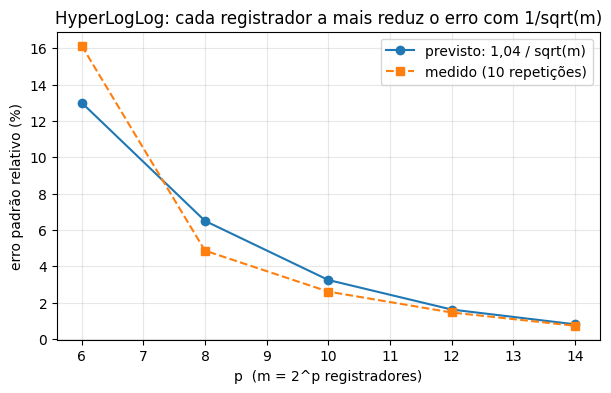

In [6]:
amostra = numeros[:100_000]
valores_p = [6, 8, 10, 12, 14]
erros_medidos = []
erros_previstos = []

for p_teste in valores_p:
    m_teste = 2 ** p_teste
    erros = []
    for repeticao in range(10):
        sal = repeticao.to_bytes(16, "big")
        regs = [0] * m_teste
        for numero in amostra:
            h = int.from_bytes(hashlib.blake2b(numero.encode(), digest_size=8, salt=sal).digest(), "big")
            j = h >> (64 - p_teste)
            resto = h & ((1 << (64 - p_teste)) - 1)
            rho = (64 - p_teste) - resto.bit_length() + 1
            if rho > regs[j]:
                regs[j] = rho
        estimado = hll_estimar(regs)
        erros.append((estimado - len(amostra)) / len(amostra))
    media = sum(erros) / len(erros)
    variancia = 0.0
    for e in erros:
        variancia = variancia + (e - media) ** 2
    desvio = math.sqrt(variancia / (len(erros) - 1))
    erros_medidos.append(desvio)
    erros_previstos.append(1.04 / math.sqrt(m_teste))
    print(f"p={p_teste:2d}  m={m_teste:6d}  desvio medido {desvio:.2%}  previsto {1.04 / math.sqrt(m_teste):.2%}")

previstos_pct = []
medidos_pct = []
for i in range(len(valores_p)):
    previstos_pct.append(erros_previstos[i] * 100)
    medidos_pct.append(erros_medidos[i] * 100)

plt.figure(figsize=(7, 4))
plt.plot(valores_p, previstos_pct, "o-", label="previsto: 1,04 / sqrt(m)")
plt.plot(valores_p, medidos_pct, "s--", label="medido (10 repetições)")
plt.xlabel("p  (m = 2^p registradores)")
plt.ylabel("erro padrão relativo (%)")
plt.title("HyperLogLog: cada registrador a mais reduz o erro com 1/sqrt(m)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### Fusão

Duas listas estaduais com números em comum. A soma das contagens superestima a união; a fusão dos *sketches*, pelo máximo registrador a registrador, estima a união diretamente — e é idêntica ao *sketch* calculado sobre a união.

In [7]:
lista_sp = numeros[:300_000]
lista_rj = numeros[200_000:450_000]       # 100.000 números em comum com lista_sp

regs_sp = [0] * m
for numero in lista_sp:
    hll_inserir(regs_sp, p, numero)
regs_rj = [0] * m
for numero in lista_rj:
    hll_inserir(regs_rj, p, numero)

regs_fundidos = []
for j in range(m):
    regs_fundidos.append(max(regs_sp[j], regs_rj[j]))

regs_uniao = [0] * m
for numero in set(lista_sp) | set(lista_rj):
    hll_inserir(regs_uniao, p, numero)

uniao_exata = len(set(lista_sp) | set(lista_rj))
print("união exata:              ", uniao_exata)
print("soma das contagens exatas:", len(lista_sp) + len(lista_rj))
print("estimativa da fusão:      ", round(hll_estimar(regs_fundidos)))
print("fusão igual ao sketch da união?", regs_fundidos == regs_uniao)

união exata:               450000
soma das contagens exatas: 550000
estimativa da fusão:       452263
fusão igual ao sketch da união? True


## MinHash

A assinatura de um conjunto para a função $h$ é $\min_{x \in A} h(x)$, e $\Pr[\text{mh}(A) = \text{mh}(B)] = J(A, B)$. Como os números de telefone são inteiros, as $k$ funções de *hash* podem ser da família universal $h_i(x) = (a_i x + b_i) \bmod P$, com $P$ primo maior que os números e $a_i, b_i$ sorteados (LESKOVEC; RAJARAMAN; ULLMAN, 2020, cap. 3).

Os dados são os cadastros de clientes de duas empresas, com sobreposição conhecida.

In [8]:
cadastro_a = set(numeros[:20_000])
cadastro_b = set(numeros[12_000:32_000])   # 8.000 em comum

intersecao = len(cadastro_a & cadastro_b)
uniao = len(cadastro_a | cadastro_b)
jaccard_exato = intersecao / uniao
print("interseção:", intersecao, " união:", uniao)
print("Jaccard exato:", round(jaccard_exato, 4))

P = 2 ** 61 - 1                             # primo de Mersenne, maior que qualquer número de 15 dígitos

def como_inteiro(numero):
    return int(numero[1:])                  # remove o "+"

def sortear_funcoes(k, semente):
    gerador = random.Random(semente)
    funcoes = []
    for i in range(k):
        a = gerador.randint(1, P - 1)
        b = gerador.randint(0, P - 1)
        funcoes.append((a, b))
    return funcoes

def assinatura(conjunto, funcoes):
    resultado = []
    for a, b in funcoes:
        menor = P
        for numero in conjunto:
            valor = (a * como_inteiro(numero) + b) % P
            if valor < menor:
                menor = valor
        resultado.append(menor)
    return resultado

def jaccard_estimado(assin_a, assin_b):
    iguais = 0
    for i in range(len(assin_a)):
        if assin_a[i] == assin_b[i]:
            iguais = iguais + 1
    return iguais / len(assin_a)

funcoes = sortear_funcoes(200, semente=1)
assin_a = assinatura(cadastro_a, funcoes)
assin_b = assinatura(cadastro_b, funcoes)
print("Jaccard estimado com k = 200:", round(jaccard_estimado(assin_a, assin_b), 4))
print("erro padrão previsto sqrt(J(1-J)/k):", round(math.sqrt(jaccard_exato * (1 - jaccard_exato) / 200), 4))
print("tamanho de cada assinatura:", 200 * 8, "bytes, contra", len(cadastro_a), "números do cadastro")

interseção: 8000  união: 32000
Jaccard exato: 0.25


Jaccard estimado com k = 200: 0.27
erro padrão previsto sqrt(J(1-J)/k): 0.0306
tamanho de cada assinatura: 1600 bytes, contra 20000 números do cadastro


### Erro em função de $k$

Com $k = 500$ funções, as estimativas para $k$ menores usam as primeiras $k$ posições da mesma assinatura. Cada ponto é o desvio padrão de 10 sorteios independentes das funções.

k=  10  desvio medido 0.1432  previsto 0.1369
k=  25  desvio medido 0.0835  previsto 0.0866
k=  50  desvio medido 0.0467  previsto 0.0612
k= 100  desvio medido 0.0346  previsto 0.0433
k= 200  desvio medido 0.0243  previsto 0.0306
k= 500  desvio medido 0.0128  previsto 0.0194


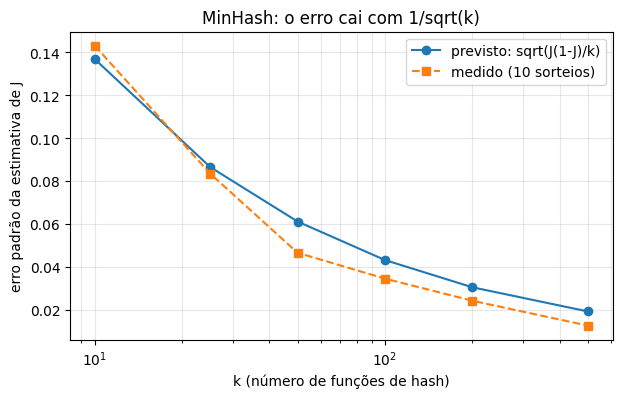

In [9]:
valores_k = [10, 25, 50, 100, 200, 500]
estimativas_por_k = {}
for k in valores_k:
    estimativas_por_k[k] = []

for sorteio in range(10):
    funcoes = sortear_funcoes(500, semente=100 + sorteio)
    assin_a = assinatura(cadastro_a, funcoes)
    assin_b = assinatura(cadastro_b, funcoes)
    for k in valores_k:
        estimativas_por_k[k].append(jaccard_estimado(assin_a[:k], assin_b[:k]))

desvios = []
previstos = []
for k in valores_k:
    lista = estimativas_por_k[k]
    soma_quadrados = 0.0
    for e in lista:
        soma_quadrados = soma_quadrados + (e - jaccard_exato) ** 2
    desvio = math.sqrt(soma_quadrados / len(lista))
    desvios.append(desvio)
    previstos.append(math.sqrt(jaccard_exato * (1 - jaccard_exato) / k))
    print(f"k={k:4d}  desvio medido {desvio:.4f}  previsto {previstos[-1]:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(valores_k, previstos, "o-", label="previsto: sqrt(J(1-J)/k)")
plt.plot(valores_k, desvios, "s--", label="medido (10 sorteios)")
plt.xscale("log")
plt.xlabel("k (número de funções de hash)")
plt.ylabel("erro padrão da estimativa de J")
plt.title("MinHash: o erro cai com 1/sqrt(k)")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()